# Анализ продаж Fitness Club

В ноутбуке сравниваем оплаты по месяцам и каналам продаж и смотрим, какие товары принесли наибольшую валовую прибыль. Все данные синтетические и используются только в учебных целях.

## Подключение и данные

Три запроса из [04_analysis.sql](../sql/04_analysis.sql) выполняются в локальной базе PostgreSQL `fitness_club_db`. Сохранённые результаты охватывают заказы с **1 января 2025 года по 30 сентября 2026 года**.

Запускайте ноутбук из корня проекта или из папки `notebooks`. Для обновления результатов из PostgreSQL подготовьте базу по инструкции в [README](../README.md).

Загрузка необходимых библиотек

In [ ]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.analysis_data import load_analysis_results
from src.plots import plot_monthly_payments, plot_sales_channels, plot_top_products

### Загрузка результатов

`load_analysis_results()` из [analysis_data.py](../src/analysis_data.py) возвращает три таблицы в порядке «месяцы, каналы, товары». Если в `data/outputs` есть все три CSV, функция читает их. При `refresh=True` или отсутствии одного из файлов функция запрашивает пароль PostgreSQL, выполняет запросы и сохраняет результаты в CSV.

При чтении CSV функция проверяет обязательные колонки и ключи. В таблице по месяцам должна быть одна строка на `order_month`, в таблице каналов — на `sales_channel_id`, в таблице товаров — на `product_id`. При нарушении этих условий сообщение об ошибке указывает имя CSV.

Функции из [plots.py](../src/plots.py) строят графики по этим таблицам. После обновления через `load_analysis_results(refresh=True)` заново выполните ячейки с графиками и сверьте текстовые выводы с новыми результатами. Текущие выводы относятся к сохранённой выгрузке.

In [ ]:
monthly_payments, sales_channels, products = load_analysis_results()

## 1. Оплаты по месяцам

**Вопрос.** В каком месяце оплаты за вычетом возвратов были наибольшими?

Суммы сгруппированы по месяцу оформления заказа. Возврат относится к тому же месяцу, что и соответствующий заказ. В таблице суммы приведены в тысячах рублей.

In [29]:
monthly_payments

,order_month,paid_thousand_rub,refunded_thousand_rub,net_paid_thousand_rub
0,2025-01-01,952.43780,227.87245,724.56535
1,2025-02-01,805.33815,255.49400,549.84415
2,2025-03-01,1055.67550,173.86150,881.81400
3,2025-04-01,869.98690,108.21265,761.77425
4,2025-05-01,793.13735,131.16250,661.97485
5,2025-06-01,820.92500,129.72950,691.19550
6,2025-07-01,826.09400,106.96250,719.13150
7,2025-08-01,842.81480,34.90400,807.91080
8,2025-09-01,929.14690,154.60350,774.54340
9,2025-10-01,881.64600,196.08850,685.55750


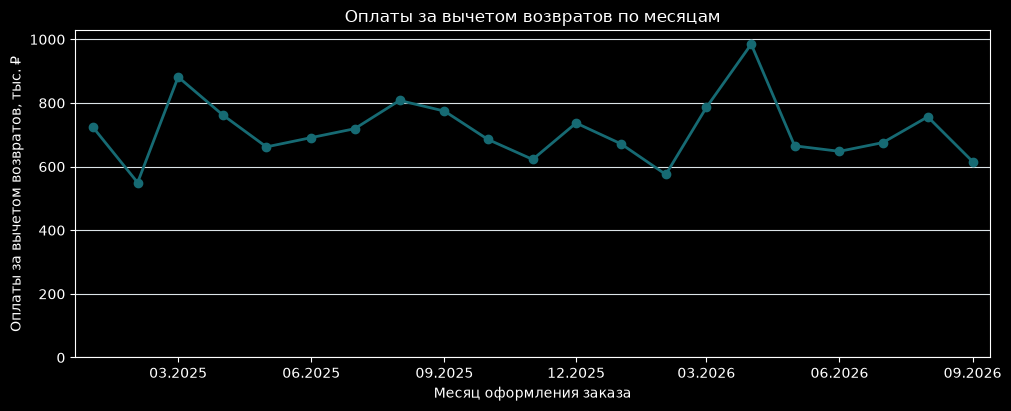

In [ ]:
plot_monthly_payments(monthly_payments)

**Вывод.** В апреле 2026 года оплаты за вычетом возвратов достигли максимума за рассматриваемый период и составили **984,86 тыс. ₽**.

## 2. Каналы продаж

**Вопрос.** Какой канал лидирует по оплатам за вычетом возвратов и в каком канале возвраты встречались чаще всего?

На графике показана сумма оплат после возвратов. Доля заказов с возвратом в таблице рассчитана от общего числа заказов каждого канала.

In [31]:
sales_channels

,sales_channel_id,sales_channel,total_order_count,refunded_count,refunded_order_pct,net_paid_thousand_rub
0,CH-003,Телефон,380,46,12.11,4271.27845
1,CH-002,Магазин,366,43,11.75,3468.04305
2,CH-004,Маркетплейс,365,50,13.70,3978.24215
3,CH-001,Сайт,344,42,12.21,3279.12945


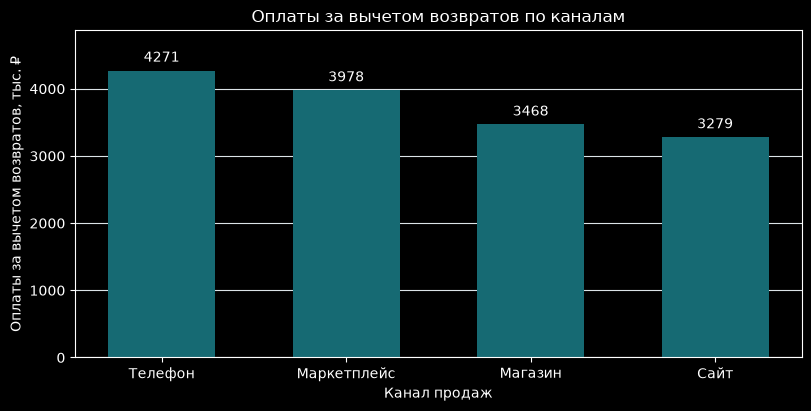

In [ ]:
plot_sales_channels(sales_channels)

**Вывод.** Канал «Телефон» лидировал по оплатам за вычетом возвратов с результатом **4 271,28 тыс. ₽**. Самая высокая доля заказов с возвратом у канала «Маркетплейс» — **13,70%** (50 из 365 заказов).

## 3. Товары

**Вопрос.** Какие товары принесли наибольшую валовую прибыль?

Сумма продаж учитывает скидки на позиции, а валовая прибыль равна сумме продаж за вычетом себестоимости. Расчёт включает позиции всех заказов и выполнен до вычета возвратов. На графике показаны десять товаров с наибольшей валовой прибылью.

In [33]:
products

,product_id,product_name,sales_rub_thd,gross_profit_rub_thd
0,PRD-028,Беговая дорожка,6469.32050,2298.13350
1,PRD-027,Велотренажёр,2879.63050,1017.69850
2,PRD-022,Кроссовки беговые,1647.97950,584.13350
3,PRD-026,Скамья складная,1245.01250,445.09250
4,PRD-006,Гиря 16 кг,1186.35000,424.06700
5,PRD-023,Кроссовки для зала,1025.50600,373.42900
6,PRD-024,Пульсометр,911.30475,325.15375
7,PRD-005,Гантель 10 кг,906.60150,318.26950
8,PRD-025,Фитнес-браслет,808.20925,286.34625
9,PRD-029,Петли тренировочные,665.81275,236.56675


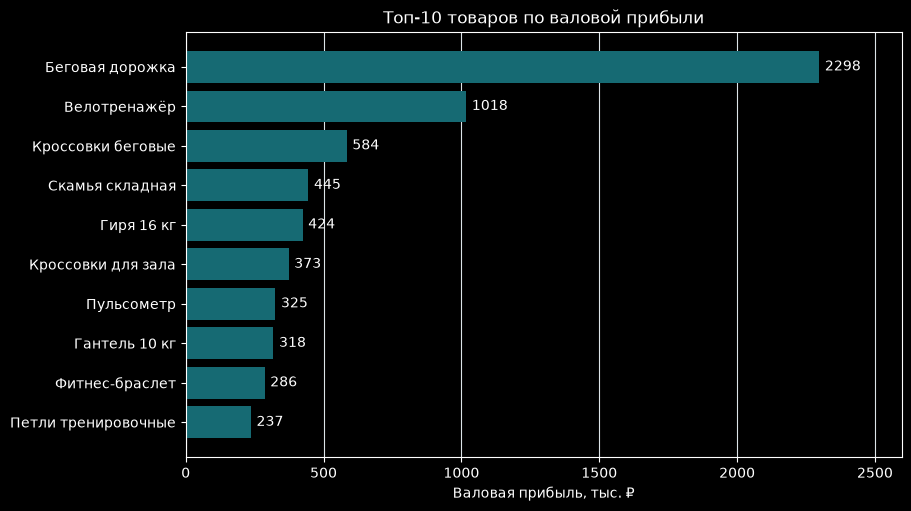

In [ ]:
plot_top_products(products)

**Вывод.** Товар «Беговая дорожка» занял первое место по валовой прибыли. Она составила **2 298,13 тыс. ₽** при сумме продаж **6 469,32 тыс. ₽** после скидок.